# Free-path 随机游走：连续冷却与分立 pp 碰撞

分析 `transport_free_path.hpp` 写出的两组数据：`transport_walk_continuous_t1e9` 和 `transport_walk_discrete_t1e9`。从原点瞬时注入等权质子，初始总能量在 10–$10^6$ GeV 对数等间隔；包括扩散、线性风 $u_z=az$、绝热冷却与 pp 能损，无逃逸边界。

当前步长约定：$\lambda=2(\mathcal R/10\,\mathrm{GV})^{1/3}$ pc，$\Delta t_{\rm full}=\lambda/(2c)$，位移长度 $\lambda\sqrt{\Delta t/\Delta t_{\rm full}}$，因而 $D=c\lambda/3$。这是按扩散系数标定的固定长度随机游走，不是以光速进行的真实自由飞行，也不是指数分布的自由程。快照和终止时刻的缩短步仍保持同样的扩散方差。

两种模型按粒子共享方向随机数，但由于冷却不同、物理步长不同，不应视为相同物理时刻的共同布朗增量。连续模型使用 RK4，分立模型用 rate thinning 抽样碰撞。连续模型碰撞计数为 −1，表示未定义。

本 notebook 只读取现有输出，不重新运行昂贵的生产模拟。可从项目根目录或 `output/` 执行。若 `_parameters.txt` 缺失，会显式采用当前头文件参数作为**未被运行元数据证实的假设**；不能从二进制恢复密度、风梯度、非弹性度或 step_fraction。


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

continuous_prefix = 'transport_walk_continuous_t1e9'
discrete_prefix = 'transport_walk_discrete_t1e9'
data_dir = Path('.')
if not (data_dir / (continuous_prefix + '_final.bin')).exists():
    data_dir = Path('output')
m_p = 0.938272              # GeV
c_cm_s = 2.99792458e10
yr2s = 31557600.0


def read_parameters(prefix):
    parameters = {}
    parameter_file = data_dir / (prefix + '_parameters.txt')
    if not parameter_file.exists():
        print('Missing metadata:', parameter_file)
        print('Assuming current transport_free_path.hpp parameters; verify against the run source.')
        parameters = {'stochastic': float(prefix == discrete_prefix),
                      'N_particles': 10000.0, 'T_end_yr': 1e9,
                      'nH_cm-3': 0.1, 'a_yr-1': 1e-8, 'kappa': 0.5,
                      'E_min_GeV': 10.0, 'E_max_GeV': 1e6,
                      'R_earth_pc': 8000.0, 'tube_radius_pc': 100.0,
                      'step_fraction': 1.0, 'seed': 12345.0}
        return parameters
    with open(parameter_file) as file:
        for line in file:
            name, value = line.split()
            parameters[name] = float(value)
    return parameters


parameters_c = read_parameters(continuous_prefix)
parameters_d = read_parameters(discrete_prefix)
for name in parameters_c:
    if name != 'stochastic':
        assert parameters_c[name] == parameters_d[name], 'Mismatched parameter: ' + name
assert parameters_c['stochastic'] == 0 and parameters_d['stochastic'] == 1
N = int(parameters_c['N_particles'])
T_end = parameters_c['T_end_yr']
nH = parameters_c['nH_cm-3']
a = parameters_c['a_yr-1']
kappa = parameters_c['kappa']

# Native-endian float64, eight columns:
# id, time[yr], E_initial[GeV], x[pc], y[pc], z[pc], E_total[GeV], collision count.
final_c = np.fromfile(data_dir / (continuous_prefix + '_final.bin'), dtype='=f8').reshape(-1, 8)
final_d = np.fromfile(data_dir / (discrete_prefix + '_final.bin'), dtype='=f8').reshape(-1, 8)
assert final_c.shape == final_d.shape == (N, 8)
assert np.array_equal(final_c[:, :3], final_d[:, :3])
assert np.array_equal(final_c[:, 0], np.arange(N))
assert np.all(final_c[:, 7] == -1)  # continuous model has no collision count
T0 = final_c[:, 2] - m_p
T_c = final_c[:, 6] - m_p
T_d = final_d[:, 6] - m_p
N_collisions = final_d[:, 7].astype(int)

# Writer groups records by particle, then orders snapshots by time.
history_c = np.fromfile(data_dir / (continuous_prefix + '_snapshots.bin'), dtype='=f8').reshape(N, -1, 8)
history_d = np.fromfile(data_dir / (discrete_prefix + '_snapshots.bin'), dtype='=f8').reshape(N, -1, 8)
assert np.array_equal(history_c[:, :, :3], history_d[:, :, :3])
assert np.array_equal(history_c[:, -1, :], final_c)
assert np.array_equal(history_d[:, -1, :], final_d)
times = history_c[0, :, 1]
# Occupancy columns: id, E_total[GeV], step-end time[yr], dt[yr].
occupancy_c = np.fromfile(data_dir / (continuous_prefix + '_occupancy.bin'), dtype='=f8').reshape(-1, 4)
occupancy_d = np.fromfile(data_dir / (discrete_prefix + '_occupancy.bin'), dtype='=f8').reshape(-1, 4)
print('Particles:', N, '| duration [yr]:', T_end, '| step_fraction:', parameters_c['step_fraction'])
print('Occupancy records (continuous, discrete):', len(occupancy_c), len(occupancy_d))
print('Mean final kinetic energy [GeV]:', T_c.mean(), T_d.mean())
print('Relative mean change (discrete - continuous) / continuous:', T_d.mean() / T_c.mean() - 1)
print('Uncollided MC fraction:', np.mean(N_collisions == 0))
assert np.all(final_c[:, 1] == T_end) and np.all(final_d[:, 1] == T_end)
assert np.all(T_c > 0) and np.all(T_d > 0)
assert np.all(N_collisions >= 0)
E_start = np.exp(np.linspace(np.log(parameters_c['E_min_GeV']),
                              np.log(parameters_c['E_max_GeV']), N))
assert np.allclose(final_c[:, 2], E_start)
for history in [history_c, history_d]:
    assert np.all(np.diff(history[:, :, 1], axis=1) > 0)
    assert np.allclose(history[:, :, 1], times[None, :])
for records in [occupancy_c, occupancy_d]:
    assert np.all(records[:, 3] > 0)
    assert np.all((records[:, 0] >= 0) & (records[:, 0] < N))
    assert np.all((records[:, 2] > 0) & (records[:, 2] <= T_end))
plt.rcParams.update({'font.size': 13, 'axes.labelsize': 15, 'axes.titlesize': 14,
                     'lines.linewidth': 2.3, 'figure.dpi': 120})


Missing metadata: output/transport_walk_continuous_t1e9_parameters.txt
Assuming current transport_free_path.hpp parameters; verify against the run source.
Missing metadata: output/transport_walk_discrete_t1e9_parameters.txt
Assuming current transport_free_path.hpp parameters; verify against the run source.
Particles: 10000 | duration [yr]: 1000000000.0 | step_fraction: 1.0
Occupancy records (continuous, discrete): 13157304 12531119
Mean final kinetic energy [GeV]: 398.5033086416606 353.17043148114305
Relative mean change (discrete - continuous) / continuous: -0.11375784385590004
Uncollided MC fraction: 0.0453


## 1. 末态质子能谱

横轴统一为动能 $T=E-m_p$。纵轴为 counts/$\Delta\ln T$，即 $dN/d\ln T$ 的 bin 平均值。残差只显示连续预测计数非零的 bin；若分立结果超出连续能谱支持区间，仍在上图显示，不对零分母计算相对残差。

这些是两种模型的样本谱，不把连续版称为分立模型的“真值”。相同初始能量和相同空间随机流会造成两种输出相关，故不使用独立 Poisson 误差作为两者差异的显著性。

Particles included in common bins: 10000 10000


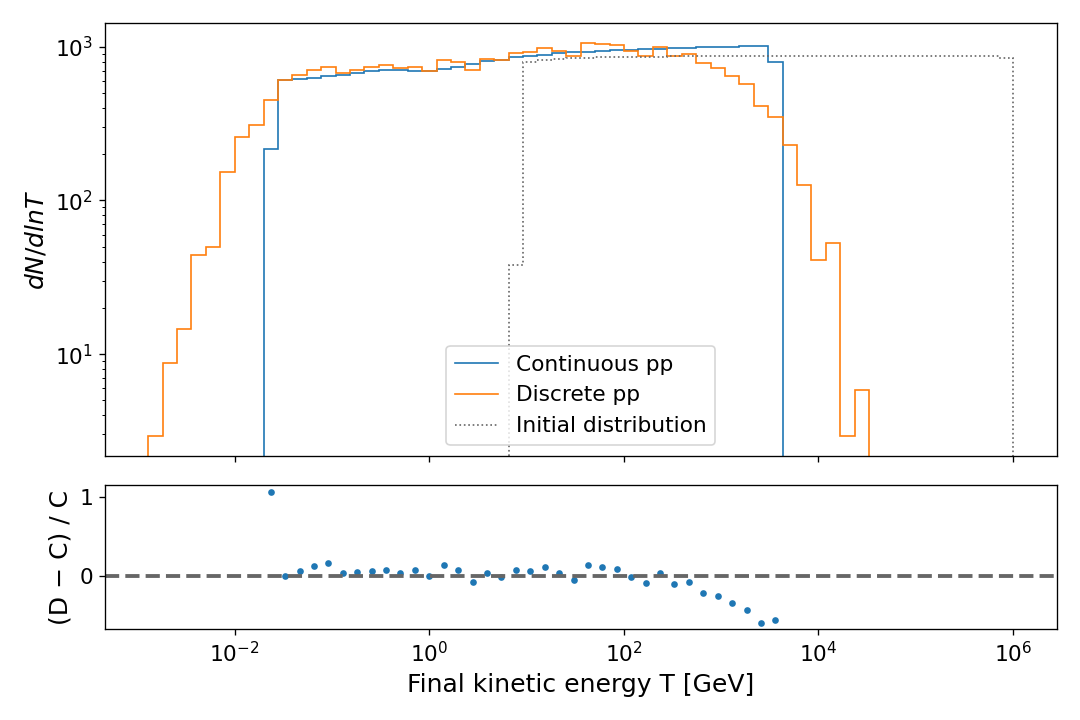

In [2]:
energy_bins = np.logspace(np.log10(min(T_c.min(), T_d.min()) * 0.99), np.log10(max(T0.max(), T_c.max(), T_d.max()) * 1.01), 61)
energy_centers = np.sqrt(energy_bins[:-1] * energy_bins[1:])
dlnT = np.diff(np.log(energy_bins))
counts_c = np.histogram(T_c, bins=energy_bins)[0]
counts_d = np.histogram(T_d, bins=energy_bins)[0]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
axes[0].stairs(counts_c / dlnT, energy_bins, label='Continuous pp')
axes[0].stairs(counts_d / dlnT, energy_bins, label='Discrete pp')
axes[0].stairs(np.histogram(T0, bins=energy_bins)[0] / dlnT, energy_bins,
               color='0.4', linestyle=':', label='Initial distribution')
axes[0].set_yscale('log')
axes[0].set_ylabel(r'$dN/dln T$')
axes[0].legend()
good = counts_c > 0
axes[1].plot(energy_centers[good], (counts_d[good] - counts_c[good]) / counts_c[good], 'o', ms=3)
axes[1].axhline(0, color='0.4', linestyle='--')
axes[1].set_xscale('log')
axes[1].set_xlabel('Final kinetic energy T [GeV]')
axes[1].set_ylabel('(D − C) / C')
fig.tight_layout()
plt.show()
print('Particles included in common bins:', counts_c.sum(), counts_d.sum())

## 2. 能谱与平均能量随时间演化

选择四个共同快照比较谱形；能谱分箱覆盖所有快照。均值、16%–84% 分位区间和平均动能比随时间显示。分位区间反映粒子群分布，不是均值误差棒；宽初始谱本身也贡献谱宽。

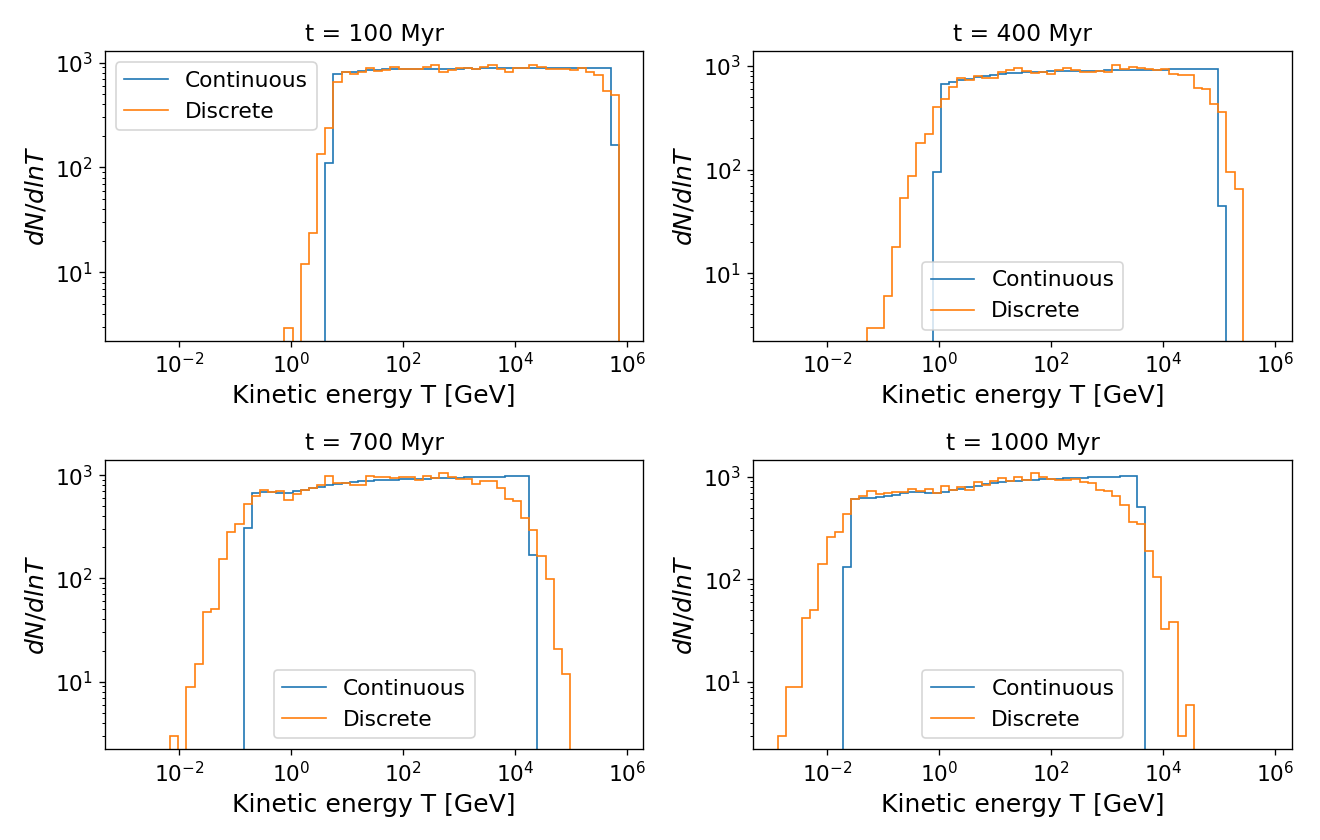

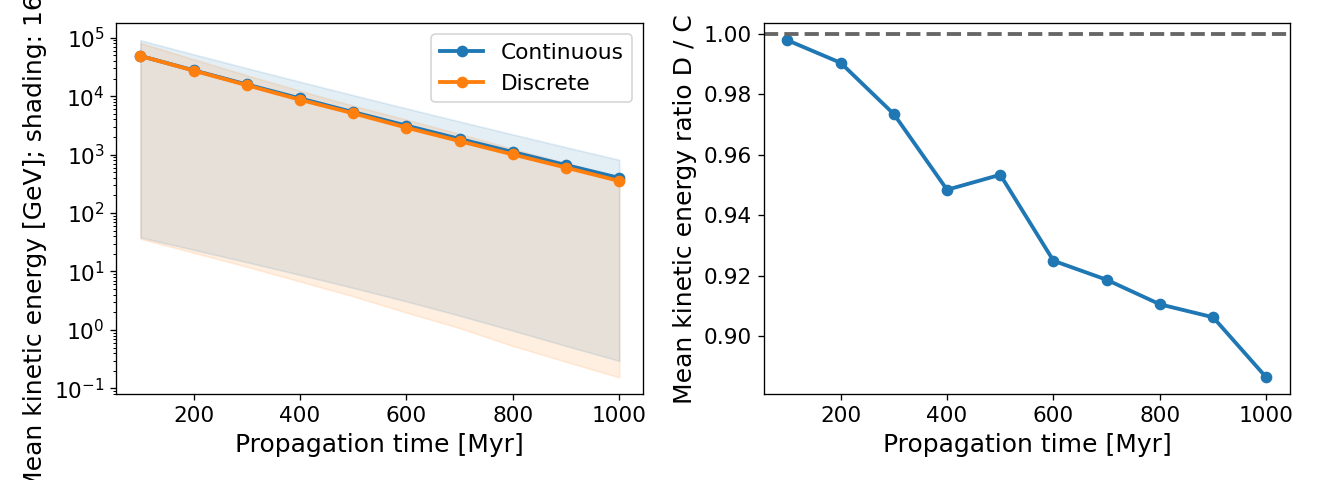

In [3]:
T_history_c = history_c[:, :, 6] - m_p
T_history_d = history_d[:, :, 6] - m_p
snapshot_bins = np.logspace(np.log10(min(T_history_c.min(), T_history_d.min()) * 0.99), np.log10(max(T_history_c.max(), T_history_d.max()) * 1.01), 61)
snapshot_width = np.diff(np.log(snapshot_bins))
selected_times = np.linspace(0, len(times) - 1, 4).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, j in zip(axes.flat, selected_times):
    ax.stairs(np.histogram(T_history_c[:, j], bins=snapshot_bins)[0] / snapshot_width, snapshot_bins, label='Continuous')
    ax.stairs(np.histogram(T_history_d[:, j], bins=snapshot_bins)[0] / snapshot_width, snapshot_bins, label='Discrete')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Kinetic energy T [GeV]')
    ax.set_ylabel(r'$dN/dln T$')
    ax.set_title(f't = {times[j] / 1e6:.0f} Myr')
    ax.legend()
fig.tight_layout()
plt.show()

mean_c = T_history_c.mean(axis=0)
mean_d = T_history_d.mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for T_history, label in [(T_history_c, 'Continuous'), (T_history_d, 'Discrete')]:
    low, high = np.percentile(T_history, [16, 84], axis=0)
    line = axes[0].plot(times / 1e6, T_history.mean(axis=0), 'o-', label=label)[0]
    axes[0].fill_between(times / 1e6, low, high, color=line.get_color(), alpha=0.12)
axes[0].set_yscale('log')
axes[0].set_ylabel('Mean kinetic energy [GeV]; shading: 16–84%')
axes[0].legend()
axes[1].plot(times / 1e6, mean_d / mean_c, 'o-')
axes[1].axhline(1, color='0.4', linestyle='--')
axes[1].set_ylabel('Mean kinetic energy ratio D / C')
for ax in axes:
    ax.set_xlabel('Propagation time [Myr]')
fig.tight_layout()
plt.show()

## 3. 初始能量、冷却和未碰撞比例

未发生 pp 碰撞的粒子仍经历绝热冷却。其未碰撞概率为
$$P_0(T_0,t)=\exp\left[-\int_0^t n_Hc\,\sigma_{pp}(T_{\rm ad}(s))\,ds\right],$$
$$p_{\rm ad}^2=T_0(T_0+2m_p)e^{-2as/3},\qquad
T_{\rm ad}=\frac{p_{\rm ad}^2}{\sqrt{m_p^2+p_{\rm ad}^2}+m_p}.$$
下面对每个粒子的无碰撞绝热轨迹积分碰撞率。分组统计误差尺度为 $\sqrt{\sum_iP_{0,i}(1-P_{0,i})}/N_{\rm bin}$。这是零碰撞概率参考，不是连续冷却模型的碰撞次数。


Survival reference refinement, max absolute change: 1.5353317298072433e-08
Mean P0 (MC, reference): 0.0453 0.04509158018202121
Expected standard error: 0.0020481870884284594


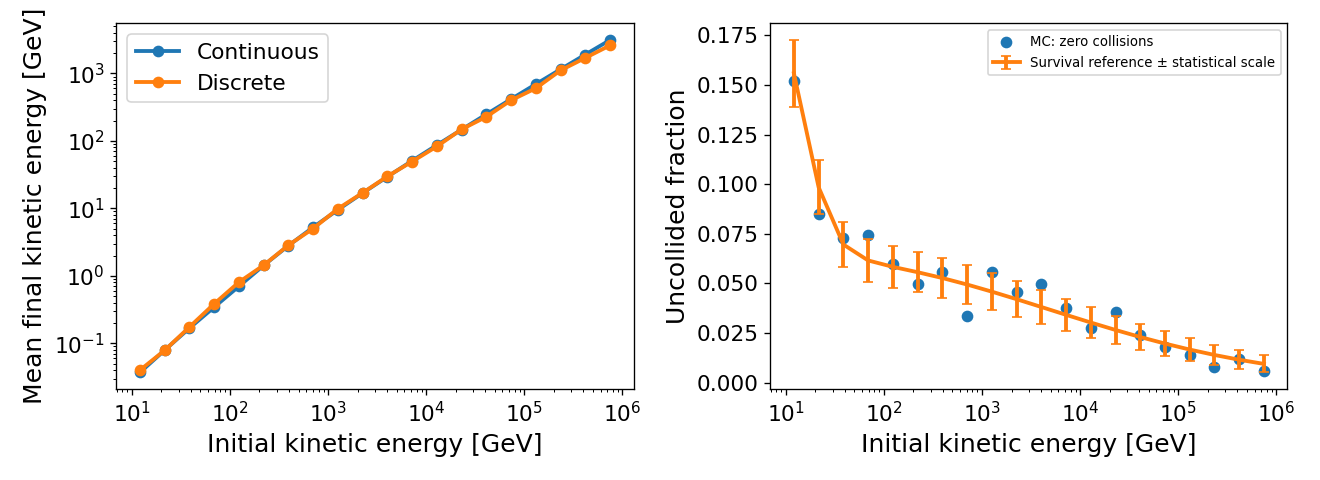

In [4]:
def sigma_pp(T):
    safe = np.maximum(T, 0.2797)
    L = np.log(safe / 0.2797)
    sigma = (30.7 - 0.96 * L + 0.18 * L**2) * (1 - (0.2797 / safe)**1.9)**3 * 1e-27
    return np.where(T > 0.2797, sigma, 0.0)


def survival_probability(N_time):
    # Trapezoidal integration of Gamma along each particle's adiabatic-only
    # trajectory; use a time loop to avoid a large particle-by-time array.
    integration_times = np.linspace(0, T_end, N_time)
    optical_depth = np.zeros(N)
    previous_rate = nH * c_cm_s * yr2s * sigma_pp(T0)
    for j in range(1, N_time):
        p2 = T0 * (T0 + 2 * m_p) * np.exp(-2 * a * integration_times[j] / 3)
        T_ad = p2 / (np.sqrt(m_p**2 + p2) + m_p)
        rate = nH * c_cm_s * yr2s * sigma_pp(T_ad)
        optical_depth += (previous_rate + rate) / 2 * (integration_times[j] - integration_times[j-1])
        previous_rate = rate
    return np.exp(-optical_depth)


P0 = survival_probability(2049)
P0_fine = survival_probability(4097)
print('Survival reference refinement, max absolute change:', np.max(np.abs(P0 - P0_fine)))
print('Mean P0 (MC, reference):', np.mean(N_collisions == 0), P0.mean())
print('Expected standard error:', np.sqrt(np.sum(P0 * (1 - P0))) / N)
initial_bins = np.logspace(np.log10(T0.min() * 0.999), np.log10(T0.max() * 1.001), 21)
initial_centers = np.sqrt(initial_bins[:-1] * initial_bins[1:])
conditional_c = np.zeros(20)
conditional_d = np.zeros(20)
zero_mc = np.zeros(20)
zero_reference = np.zeros(20)
zero_error = np.zeros(20)
for j in range(20):
    selected = (T0 >= initial_bins[j]) & (T0 < initial_bins[j+1])
    conditional_c[j] = T_c[selected].mean()
    conditional_d[j] = T_d[selected].mean()
    zero_mc[j] = np.mean(N_collisions[selected] == 0)
    zero_reference[j] = P0[selected].mean()
    zero_error[j] = np.sqrt(np.sum(P0[selected] * (1 - P0[selected]))) / selected.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(initial_centers, conditional_c, 'o-', label='Continuous')
axes[0].plot(initial_centers, conditional_d, 'o-', label='Discrete')
axes[0].set_yscale('log')
axes[0].set_ylabel('Mean final kinetic energy [GeV]')
axes[0].legend()
axes[1].plot(initial_centers, zero_mc, 'o', label='MC: zero collisions')
axes[1].errorbar(initial_centers, zero_reference, yerr=zero_error, fmt='-', capsize=3, label='Survival reference ± statistical scale')
axes[1].set_ylabel('Uncollided fraction')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('Initial kinetic energy [GeV]')
fig.tight_layout()
plt.show()

## 4. 扩散与对流的空间反馈

两种模型使用共同空间随机数，但能量变化不同会改变各自的扩散系数。因此位置不应被强制相同。比较最终柱半径 $R$、高度 $|z|$ 的累计粒子比例，以及随时间的横向均方根半径和高度。线性风无逃逸边界，会在长时间产生很大的高度；这是当前模型设置的结果。

本程序的空间随机步长度和步时均依赖能量；碰撞发生在步内时不会重新开始该空间步。空间分裂误差需要另跑较小 step_fraction 检查，本 notebook 不将连续/分立模型差异解释为数值收敛误差。

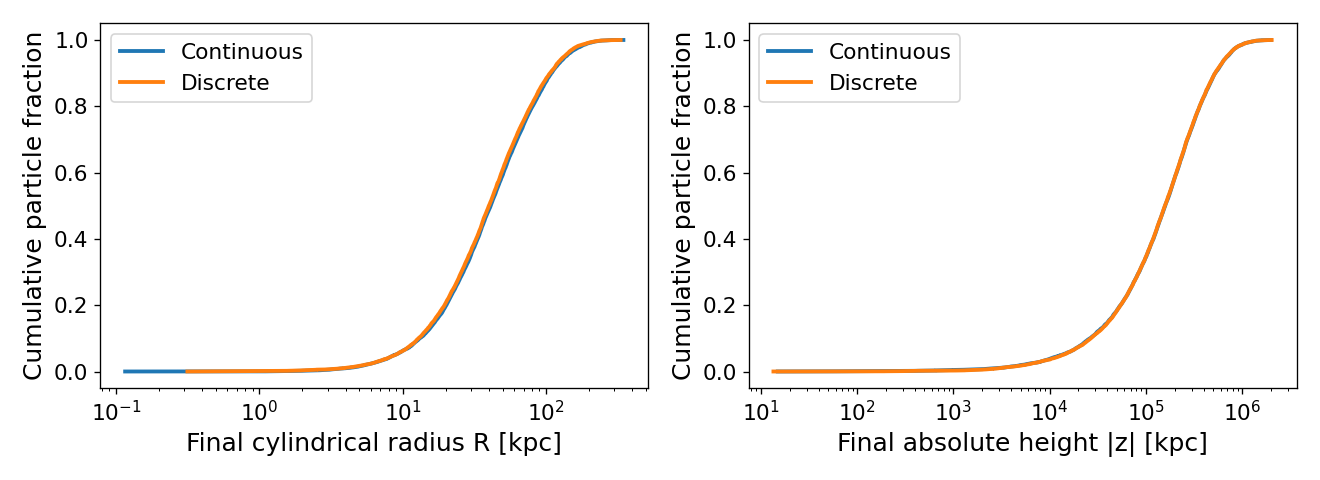

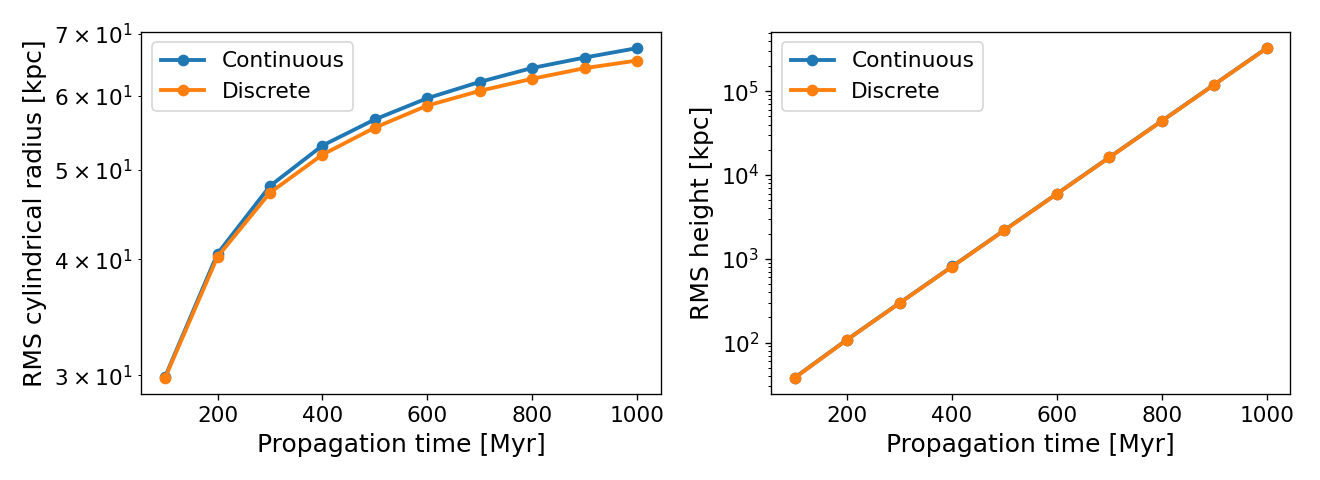

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for final, label in [(final_c, 'Continuous'), (final_d, 'Discrete')]:
    R = np.hypot(final[:, 3], final[:, 4]) / 1000
    Z = np.abs(final[:, 5]) / 1000
    for ax, coordinate in zip(axes, [R, Z]):
        ax.plot(np.sort(coordinate), np.arange(1, N + 1) / N, label=label)
for ax, label in zip(axes, ['Final cylindrical radius R [kpc]', 'Final absolute height |z| [kpc]']):
    ax.set_xscale('log')
    ax.set_xlabel(label)
    ax.set_ylabel('Cumulative particle fraction')
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for history, label in [(history_c, 'Continuous'), (history_d, 'Discrete')]:
    rms_R = np.sqrt(np.mean(history[:, :, 3]**2 + history[:, :, 4]**2, axis=0)) / 1000
    rms_z = np.sqrt(np.mean(history[:, :, 5]**2, axis=0)) / 1000
    axes[0].plot(times / 1e6, rms_R, 'o-', label=label)
    axes[1].plot(times / 1e6, rms_z, 'o-', label=label)
for ax, label in zip(axes, ['RMS cylindrical radius [kpc]', 'RMS height [kpc]']):
    ax.set_yscale('log')
    ax.set_xlabel('Propagation time [Myr]')
    ax.set_ylabel(label)
    ax.legend()
fig.tight_layout()
plt.show()

## 5. 观测环内的时间占据谱

两种模型使用同一个固定环管：$R_\oplus=8$ kpc，管半径 100 pc。每条记录按其实际步长 $\Delta t_i$ 加权，计算
$$\frac{d\overline N_{\rm ring}}{d\ln T}
=\frac{\sum_{i\in\mathrm{bin}}\Delta t_i}{t_{\rm end}\,\Delta\ln T}.$$
这是时间平均环管内粒子数谱。除以 $V=2\pi^2R_\oplus r_{\rm tube}^2$ 可得数密度谱；再除以注入粒子数 $N$ 可得每个注入粒子的响应。它不是首次到达谱，也不是穿过表面的通量。

自由程步长依赖能量，因此原始记录次数带有采样偏差，不能直接比较。端点占据权重仍有有限步长误差。重复记录相关，报告独立访问粒子数，不使用原始记录数的独立 Poisson 误差。


Continuous : records = 13157304 , visiting particles = 3325 , time-averaged ring particle count = 0.08761676655828685
Discrete : records = 12531119 , visiting particles = 3308 , time-averaged ring particle count = 0.08493204686420411


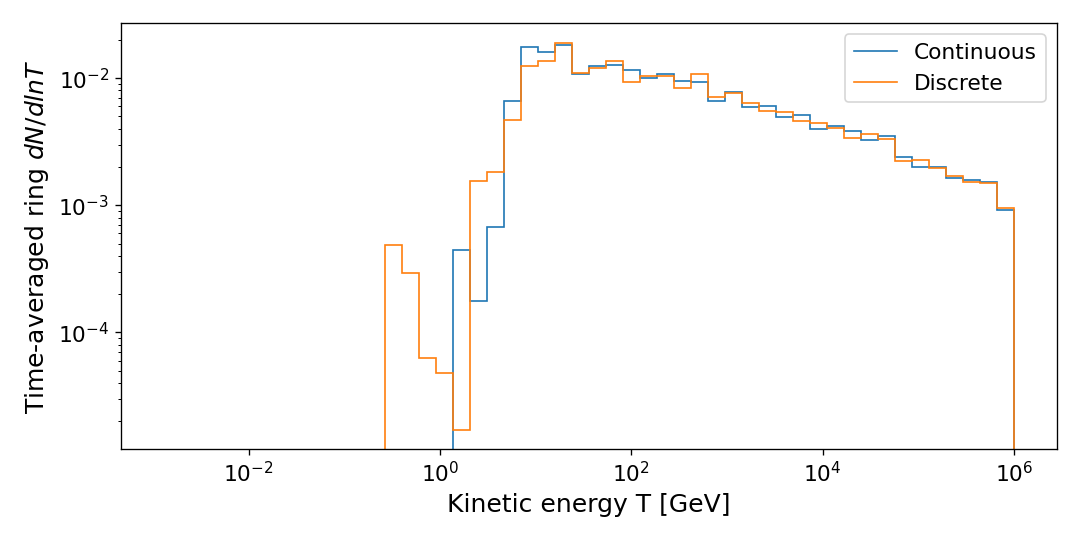

In [6]:
occupancy_energies = [T_c, T_d]
for records in [occupancy_c, occupancy_d]:
    if len(records) > 0:
        occupancy_energies.append(records[:, 1] - m_p)
local_min = min(values.min() for values in occupancy_energies)
local_max = max(values.max() for values in occupancy_energies)
local_bins = np.logspace(np.log10(local_min * 0.99), np.log10(local_max * 1.01), 51)
local_width = np.diff(np.log(local_bins))
fig, ax = plt.subplots(figsize=(9, 4.5))
for records, label in [(occupancy_c, 'Continuous'), (occupancy_d, 'Discrete')]:
    weighted_counts = np.histogram(records[:, 1] - m_p, bins=local_bins, weights=records[:, 3])[0]
    ax.stairs(weighted_counts / T_end / local_width, local_bins, label=label)
    print(label, ': records =', len(records), ', visiting particles =', len(np.unique(records[:, 0])),
          ', time-averaged ring particle count =', records[:, 3].sum() / T_end)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Kinetic energy T [GeV]')
ax.set_ylabel(r'Time-averaged ring $dN/dln T$')
ax.legend()
fig.tight_layout()
plt.show()

## 6. 总能量谱与碰撞次数

这里 $E=T+m_p$，总能量谱与前面的动能谱分别重新分箱并按各自自然对数箱宽归一化。碰撞次数仅对分立模型定义；能量相关的截面以及绝热冷却使其不能简单用单一泊松分布描述。


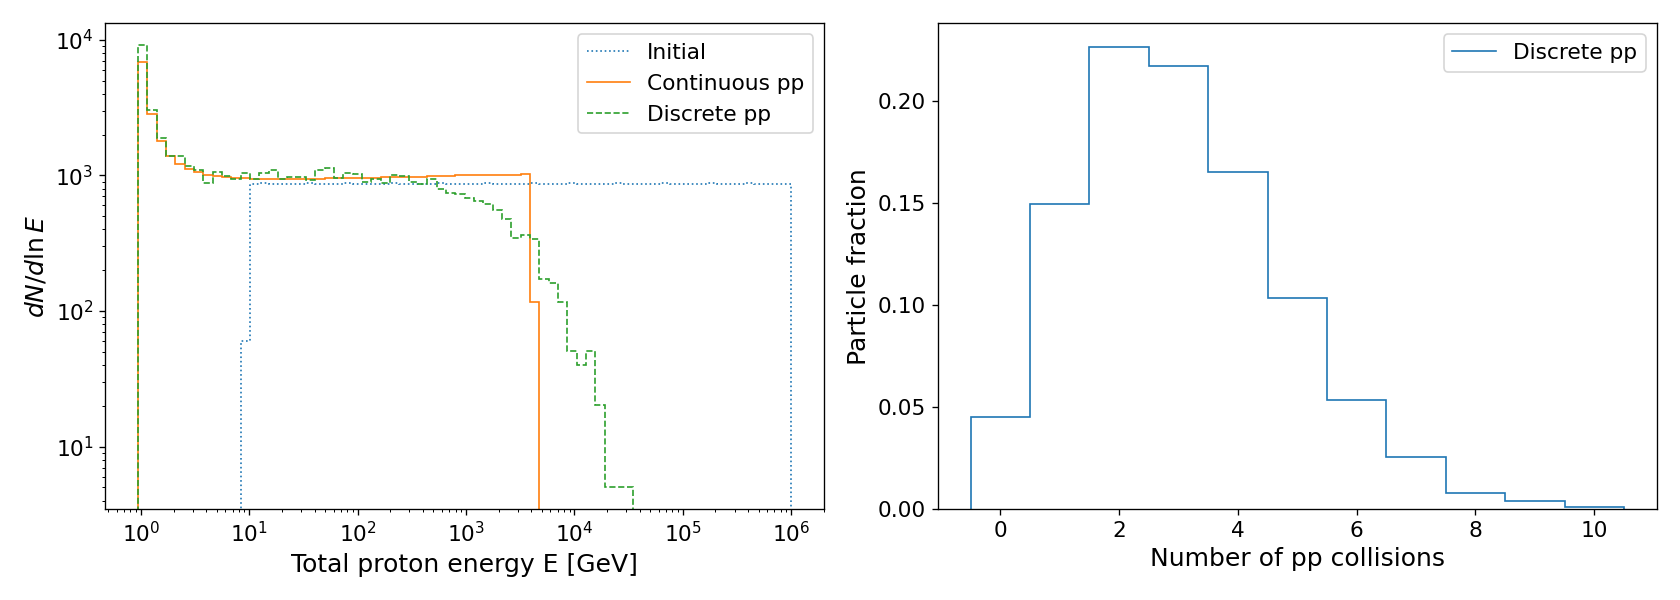

In [7]:
E_low = min(final_c[:, 6].min(), final_d[:, 6].min()) * 0.999
E_high = E_start.max() * 1.001
E_bins = np.logspace(np.log10(E_low), np.log10(E_high), 71)
dlnE = np.diff(np.log(E_bins))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for values, label, style in [(E_start, 'Initial', ':'),
                              (final_c[:, 6], 'Continuous pp', '-'),
                              (final_d[:, 6], 'Discrete pp', '--')]:
    counts = np.histogram(values, bins=E_bins)[0]
    assert counts.sum() == N
    axes[0].stairs(counts / dlnE, E_bins, linestyle=style, label=label)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Total proton energy E [GeV]')
axes[0].set_ylabel(r'$dN/d\ln E$')
axes[0].legend()
collision_bins = np.arange(N_collisions.max() + 2) - 0.5
counts = np.histogram(N_collisions, bins=collision_bins)[0]
axes[1].stairs(counts / N, collision_bins, label='Discrete pp')
axes[1].set_xlabel('Number of pp collisions')
axes[1].set_ylabel('Particle fraction')
axes[1].legend()
fig.tight_layout()
plt.show()


## 7. 观测环内按驻留时间加权的年龄分布

绘制
$$\frac{d\mathcal T_{\rm ring}}{d\ln t}=\frac{\sum_{i\in\mathrm{age\ bin}}\Delta t_i}{\Delta\ln t},$$
单位为 particle yr，积分为所有注入粒子的环管内累计驻留时间。除以 $N$ 得每个注入粒子的平均响应，除以 $t_{\rm end}$ 得时间平均占据对各年龄的贡献。此图不是原始步记录数的年龄分布，也不是首次到达时间分布。


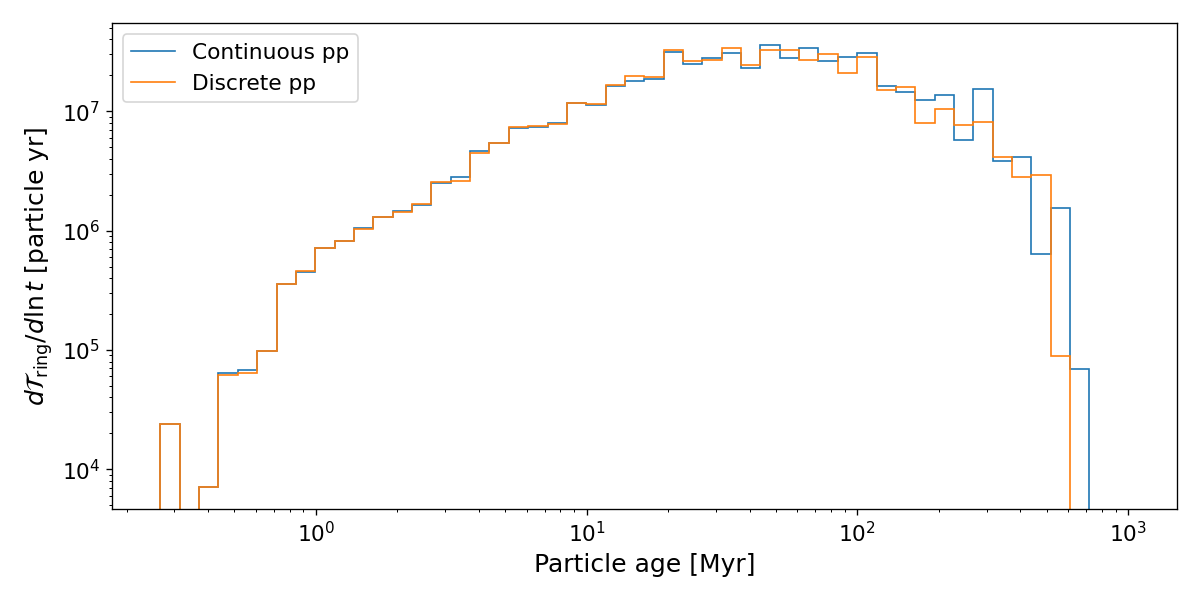

In [8]:
nonempty = [records for records in [occupancy_c, occupancy_d] if len(records) > 0]
if len(nonempty) == 0:
    print('No observing-ring records: age distribution is unavailable.')
else:
    first_age = min(records[:, 2].min() for records in nonempty)
    age_bins = np.logspace(np.log10(first_age * 0.99), np.log10(T_end), 51)
    age_bins[-1] = T_end
    dln_age = np.diff(np.log(age_bins))
    fig, ax = plt.subplots(figsize=(10, 5))
    for records, label in [(occupancy_c, 'Continuous pp'), (occupancy_d, 'Discrete pp')]:
        residence = np.histogram(records[:, 2], bins=age_bins, weights=records[:, 3])[0]
        assert np.isclose(residence.sum(), records[:, 3].sum())
        ax.stairs(residence / dln_age, age_bins / 1e6, label=label)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Particle age [Myr]')
    ax.set_ylabel(r'$d\mathcal{T}_{\rm ring}/d\ln t$ [particle yr]')
    ax.legend()
    fig.tight_layout()
    plt.show()


## 8. 独立冷却方程检查

`solve_ivp` 在归一化时间 $q=t/t_{\rm end}$ 上自适应积分所有初始粒子的 $\ln T$，并返回十个记录时刻的解。积分方程为
$$\frac{d\ln T}{dt}=-\frac a3\frac{T+2m_p}{T+m_p}-\kappa\Gamma(T).$$
输入与输出均为粒子动能的自然对数；此计算检验连续版 C++ RK4 的积分结果，不检验连续能损近似本身。分立版零碰撞粒子另与精确绝热解比较。没有假设有碰撞的粒子仅在末尾一次性损失能量。


In [9]:
from scipy.integrate import solve_ivp


def cooling_rhs(q, logT):
    T = np.exp(logT)
    rate = nH * c_cm_s * yr2s * sigma_pp(T)
    return T_end * (-a / 3 * (T + 2 * m_p) / (T + m_p) - kappa * rate)


solution = solve_ivp(cooling_rhs, (0, 1), np.log(T0), t_eval=times / T_end,
                     rtol=1e-10, atol=1e-12)
assert solution.success, solution.message
T_reference = np.exp(solution.y)
relative_error = T_history_c / T_reference - 1
print('Continuous RK4 versus independent ODE, maximum relative difference:', np.max(np.abs(relative_error)))
uncollided = N_collisions == 0
if np.any(uncollided):
    p2 = T0[uncollided] * (T0[uncollided] + 2 * m_p) * np.exp(-2 * a * T_end / 3)
    T_ad = p2 / (np.sqrt(m_p**2 + p2) + m_p)
    print('Uncollided MC versus exact adiabatic solution, max relative difference:',
          np.max(np.abs(T_d[uncollided] / T_ad - 1)))


Continuous RK4 versus independent ODE, maximum relative difference: 1.599455567991015e-08
Uncollided MC versus exact adiabatic solution, max relative difference: 5.9984499589660345e-09


## 结果的适用范围

先看全体粒子谱和按初始能量分组的冷却差异，再看这些能量差异如何反馈到空间分布和观测环谱。共同随机数可以减小某些比较中的抽样波动，但不能消除统计误差。输入谱是确定性对数网格，不应使用独立随机注入样本的 KS p 值。

当前比较检验固定非弹性度 κ=0.5 的连续与分立 pp 能损模型。它不包含完整次级粒子产生、空间变化气体密度或逃逸。连续方程的精确求解也不会消除连续近似本身与有限能量跳跃过程的差别。采用更小 dt、独立随机种子或更多粒子重跑，可分别检查数值收敛与抽样误差。

本地现有二进制缺少参数文件时，物理参数符合当前头文件仅是可检验假设，不能作为完整运行溯源。生产运行的时间步收敛需要额外的 step_fraction 配对输出；本 notebook 未自动执行模拟或宣称完成该收敛测试。